# F03.08 · La red de grafos (DCRNN) de Tang: cada electrodo con su memoria, hablando con sus vecinos

> 🧭 **En 30 segundos**
> - **Para qué:** la red de F03.06 (GRU sobre el clip de 60 s) se quedó por debajo de XGBoost dentro del paciente, y preentrenarla (F03.07) no cambió nada. Su problema: mete los 22 canales × 40 Hz de golpe en una capa densa y **se aprende a los pacientes**. Aquí se prueba la red **completa** de Tang et al. (ICLR 2022): la **DCRNN**, con un **grafo de electrodos** por clip.
> - **Entra:** exactamente los datos de F03.06 (mismo clip de 60 s, misma log-FFT por segundo, misma normalización) y las puntuaciones de XGBoost (F03.03) y de la red sin grafo (F03.06) → **Sale:** la nota en 🟡 dev de la DCRNN, la comparación con F03.06 y con XGBoost y el control de sesión.
> - **Idea clave:** los pesos son **los mismos para los 22 canales** (cada canal entra solo con sus 40 Hz) y cada canal "escucha" a los canales con los que se sincroniza en ese clip. Menos margen para memorizar y una pista nueva: **qué regiones se sincronizan**.

> 📍 **Dónde estamos: Fase 3 · notebook 8 (F03.08).** Último intento con redes antes de cerrar la Fase 3. **Regla acordada:** si no supera a XGBoost dentro del paciente, la Fase 3 se cierra con XGBoost.

> 🔄 **Es dinámico.** Lee lo que dejaron F03.01, F03.03 y F03.06; las cifras y las conclusiones salen de los datos. Lo ya entrenado se lee del registro.

> 🔒 **Regla de oro de la Fase 3: aquí no se mira 🟢 eval.** Todo se decide con 🟡 dev.

| Fase del TFM | | Estado |
|---|---|---|
| Fase 1 | Exploración de datos | ✅ terminada |
| Fase 2 | Preprocesado y ventanas | ✅ terminada |
| **Fase 3** | **Modelo de predicción (⏳ preictal frente a 💤 interictal)** | 👉 **en curso** (la fase de este notebook) |
| Fase 4 | Clasificación de tipos de crisis | pendiente |
| Fase 5 | Explicabilidad (XAI) | pendiente |
| Fase 6 | Memoria | pendiente |
| Fase 7 | Revisión y defensa | pendiente |

## 🧩 La idea, en sencillo

Piensa en una reunión de 22 personas. La red de F03.06 es un secretario que apunta **todo lo que dicen todos** en una sola hoja cada segundo: con pocos ejemplos, acaba memorizando quién habla en cada reunión. La DCRNN da **una libreta a cada persona** (su memoria) y, cada segundo, cada una apunta lo suyo **y lo que dicen las que más se le parecen** (sus vecinos en el grafo). Las 22 usan **las mismas reglas** para apuntar.

| Lo que cambia | F03.06 (GRU) | F03.08 (DCRNN, Tang) |
|---|---|---|
| **Memoria** | una para todo el EEG (64 números) | **una por canal** (22 × 64) |
| **Cómo entra cada segundo** | 22 canales × 40 Hz juntos en una capa densa | cada canal con sus 40 Hz; **los mismos pesos para todos** |
| **Relación entre canales** | la aprende la capa densa | **grafo de correlación** del clip: cada canal escucha a sus 3 vecinos más parecidos (y a los vecinos de estos) |
| **Salida** | la memoria final → un número | cada canal da un número; el logit es el **máximo** (basta con que una región "se encienda") |

![La red de grafos (DCRNN)](img/grafo_dcrnn.png)

En Tang (detección en TUSZ), sin preentrenar, la DCRNN con grafo de correlación dio 0,812 de AUROC (12 s) frente a 0,786 de su red sin grafo (LSTM).

| Pregunta | Dónde se responde |
|---|---|
| ¿Cómo es el grafo de un clip? | §4 |
| ¿La DCRNN supera a la red sin grafo (F03.06) y a XGBoost, **dentro de cada paciente**? | §7 (recuadro dorado) |
| ¿Le sirve leer 60 s o le bastan 12 s (los dos clips de Tang)? | §7 |
| ¿Aguanta el control de sesión? | §8 |

## El recorrido de este notebook

![El recorrido del notebook F03.08](img/mapa_notebook_08.png)

1. Parámetros y librerías (§0-§1) · 2. Configuración (§2) · 3. **Los datos** (§3) · 4. **Qué ve la red** (§4) · 5. Las variantes (§5) · 6. **Entrenar** (§6) · 7. **La nota frente a XGBoost y las redes anteriores** (§7) · 8. Por paciente, por grupo y control de sesión (§8) · 9. Ficheros, resumen y conclusiones (§9-§11).

### 📖 Diccionario rápido

| Término | Qué significa, en sencillo |
|---|---|
| **Clip** | Los 60 s de señal que ve la red de una vez. Su etiqueta es la de la ventana con la que **acaba** |
| **FFT** | Descompone un trozo de señal en sus frecuencias: cuánta onda de 1 Hz, de 2 Hz... hay en ese segundo |
| **Log-amplitud** | El logaritmo de esa cantidad: así 0,001 y 100 quedan en una escala parecida (Tang hace lo mismo) |
| **Quitar el nivel** | Restar a cada canal su media en la ventana de 4 s: la red ve la forma del espectro, no lo fuerte que llega la señal (pista tramposa H3 de F02.05) |
| **GRU** | Red que lee una secuencia paso a paso y lleva una memoria (F03.04 §6) |
| **Grafo** | Los canales (nodos) y quién está unido con quién (aristas). Aquí, unidos si su actividad en el clip se parece |
| **Correlación** | Cuánto se parecen dos señales: 0 = nada, 1 = igual (se usa en valor absoluto) |
| **Convolución de difusión** | "Lo mío + lo de mis vecinos + lo de los vecinos de mis vecinos", con pesos que se aprenden (K = 2 pasos) |
| **DCGRU / DCRNN** | Una GRU donde cada multiplicación es una convolución de difusión (Li et al., 2018); Tang la usa para EEG |
| **AUC dentro del paciente** | La AUC comparando solo ⏳ y 💤 **del mismo paciente** (F03.05 §2): lo que necesita una app |
| **Diferencia emparejada** | Comparar dos modelos con las mismas ventanas y los mismos sorteos de pacientes (F03.03 §9) |

## 0. Los parámetros

- `CONJUNTO`: `None` = el de `tfm_comun/prediccion/estudio.py` (el mismo para toda la Fase 3).
- `MODO_PRUEBA`: `True` para comprobar que todo funciona en pocos minutos (el 10 % de las ventanas, 1 semilla, 2 épocas). Las cifras no valen; los resultados van a una carpeta aparte, `_prueba`.
- `REENTRENAR`: `True` para volver a entrenar aunque la configuración esté en el registro.

*(La celda lleva la etiqueta `parameters` para poder lanzarla con papermill.)*

In [1]:
CONJUNTO = None   # None = el de tfm_comun/prediccion/estudio.py (el mismo en toda la Fase 3); se puede poner otro aquí
MODO_PRUEBA = False
REENTRENAR = False

## 1. Librerías

In [2]:
import sys
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'tfm_comun').is_dir())))
from tfm_comun.entorno.requisitos import comprobar_requisitos, REQUISITOS_FASE_03_RED
disponibles = comprobar_requisitos(REQUISITOS_FASE_03_RED)

,estado,versión,para qué
librería,,,
numpy,✅,2.5.4,cálculo con matrices
pandas,✅,3.0.6,tablas
matplotlib,✅,3.11.2,figuras
scipy,✅,1.18.1,espectro de cada ventana (Welch)
scikit-learn,✅,1.9.1,"regresión logística, AUROC y curvas ROC"
xgboost,✅,3.4.1,XGBoost: árboles de decisión encadenados
joblib,✅,1.6.0,guardar los modelos entrenados
tqdm,✅,4.70.1,barra de progreso al calcular las características
torch,✅,2.15.0+cu132,"la red neuronal: capas, entrenamiento en la GPU (PyTorch)"


Todo lo necesario está instalado.


In [3]:
%load_ext autoreload
%autoreload 2
for modulo in [m for m in list(sys.modules) if m == 'tfm_comun' or m.startswith('tfm_comun.')]:
    del sys.modules[modulo]

import json
from functools import partial
import time

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
import torch
from tqdm.auto import tqdm
from IPython.display import display, Markdown

from tfm_comun.entorno.rutas import RUTA_OUTPUTS_FASE_03, carpeta_resultados
from tfm_comun.entorno.versiones import mostrar_versiones
from tfm_comun.entorno.dispositivo import elegir_dispositivo
from tfm_comun.entorno.configuracion import leer_configuracion
from tfm_comun.red.preparacion import preparar_datos_red
from tfm_comun.red.entradas.log_fft_segundos import segundos_por_ventana
from tfm_comun.red.redes.dcrnn import ARQUITECTURA_DCRNN
from tfm_comun.red.modelo import crear_red, contar_parametros
from tfm_comun.red.grafo import grafo_correlacion
from tfm_comun.red.entreno.entrenar_red import ENTRENAMIENTO
from tfm_comun.red.experimentos.registro import Registro
from tfm_comun.red.entreno.variantes import EntrenadorVariantes
from tfm_comun.prediccion.evaluacion.auroc_global import auroc_con_intervalo
from tfm_comun.prediccion.evaluacion.auroc_paciente import auroc_por_paciente, auroc_dentro_paciente
from tfm_comun.prediccion.control_sesion import controles_de_sesion
from tfm_comun.prediccion.evaluacion.evaluador import Evaluador
from tfm_comun.prediccion.evaluacion.lectura import lectura_diferencia
from tfm_comun.visual.iconos import con_icono
from tfm_comun.visual.colores import COLORES_ESQUEMA
from tfm_comun.visual.numeros import numero_legible, decimal, con_intervalo, con_signo
from tfm_comun.visual.tablas import con_separadores, mostrar_destacado
from tfm_comun.visual.ficheros import mostrar_fichero
from tfm_comun.visual.tipografia import ESTILO_TIMES

versiones_usadas = mostrar_versiones(np, pd, matplotlib, scipy, sklearn, torch)

# El conjunto: si la celda de parámetros lo deja en None, el de tfm_comun/prediccion/estudio.py
from tfm_comun.prediccion.estudio import conjunto_del_estudio
CONJUNTO = conjunto_del_estudio(CONJUNTO)

Python      3.14.0
numpy       2.5.4
pandas      3.0.6
matplotlib  3.11.2
scipy       1.18.1
sklearn     1.9.1
torch       2.15.0+cu132


## 2. Configuración

> 🎯 **Qué hacemos:** fijar los "botones" del notebook y leer lo que dejaron F03.01, F03.03 y (si existe) F03.05.

| Parámetro | Valor | Qué controla |
|---|---|---|
| `N_SEMILLAS` | 3 | Cada variante se entrena 3 veces y se promedian las puntuaciones (como en F03.04 y F03.05) |
| `CONTEXTO_S` | 60 | Segundos del clip (Tang usa 12 y 60 s; F03.03 vio que mirar más atrás es lo que más ayuda) |
| `ARQUITECTURA` | `ARQUITECTURA_DCRNN` | DCGRU de 2 capas × 64 por nodo, K = 2 pasos de difusión, grafo de correlación con 3 vecinos, dropout 0,3 (`tfm_comun/red/redes/dcrnn.py`, `grafo.py`) |
| `ENTRADA` | `'log_fft_segundo'` | La misma de F03.06: log-amplitud de la FFT de cada segundo, 40 Hz por canal |
| `LOTE_EVALUACION` | 256 | Filas por lote al medir en validación. Solo cambia la memoria de la GPU, no el resultado (con 1.024, cuBLAS fallaba en Windows) |
| `NORMALIZACION` | `None` | `None` = la que decidió F03.03 (`decision_red`); se puede forzar `'ninguna'`, `'por_paciente'` o `'por_paciente_calibrado'` |
| `ESPECIFICIDAD`, `N_BOOTSTRAP`, `MEJORA_MINIMA` | 0,9 · 500 · 0,02 | Como en F03.03-F03.05 |

In [4]:
N_SEMILLAS = 3
CONTEXTO_S = 60
NORMALIZACION = None
ENTRADA = 'log_fft_segundo'
ARQUITECTURA = dict(ARQUITECTURA_DCRNN)
LOTE_EVALUACION = 256          # filas por lote al medir: con 1.024, cuBLAS fallaba en Windows (no cambia el resultado)
NOMBRE_BASE = 'dcrnn'
ESPECIFICIDAD = 0.9
N_BOOTSTRAP = 500
MEJORA_MINIMA = 0.02

In [5]:
SUFIJO = '_prueba' if MODO_PRUEBA else ''
RUTA_RESULTADOS, RUTA_FIGURAS = carpeta_resultados(f'fase_03/{CONJUNTO}/08_red_grafo' + SUFIJO)
RUTA_MODELOS = RUTA_RESULTADOS / 'modelos'
RUTA_MODELOS.mkdir(exist_ok=True)
registro = Registro(RUTA_RESULTADOS / 'registro')

# leer_config: el configuracion.json de un notebook anterior, comprobando que es de este CONJUNTO
# (tfm_comun/entorno/configuracion.py; para con un mensaje claro si falta o es de otro conjunto)
leer_config = partial(leer_configuracion, conjunto=CONJUNTO)
config_01 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '01_datos_red' / 'configuracion.json', 'F03.01 (fase_03/01_datos_red.ipynb)')
config_03 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'configuracion.json', 'F03.03 (fase_03/03_contexto_y_paciente.ipynb)')
config_05 = leer_config(RUTA_OUTPUTS_FASE_03 / CONJUNTO / ('05_mejoras_red' + SUFIJO) / 'configuracion.json', 'F03.05', obligatorio=False)
if MODO_PRUEBA:
    N_SEMILLAS = 1
SEMILLAS = [int(config_01['semilla']) + s for s in range(N_SEMILLAS)]
NORMALIZACION_USADA = NORMALIZACION or config_03['decision_red']['normalizacion']
NOMBRE_XGB = f'XGBoost F03.03 ({config_03["mejor"]["contexto_s"]} s, {config_03["mejor"]["normalizacion"]})'
NOMBRE_F0305 = f'mejor red F03.05 ({config_05["mejor"]["nombre"]})' if config_05 else None
assert CONTEXTO_S <= max(config_03['contextos_s']), (f'F03.03 solo probó contextos hasta {max(config_03["contextos_s"])} s: vuelve a ejecutarlo '
                                                     f'(tfm_comun/prediccion/contextos/ ya permite {CONTEXTO_S} s) para que las ventanas coincidan.')

dispositivo, ficha = elegir_dispositivo()

print(f'Conjunto: {CONJUNTO}{" · 🔴 MODO PRUEBA (cifras sin valor)" if MODO_PRUEBA else ""} · semillas: {SEMILLAS}')
print(f'Clip de {CONTEXTO_S} s · entrada: {ENTRADA} · normalización: {NORMALIZACION_USADA}' + (' (la de F03.03)' if NORMALIZACION is None else ' (forzada aquí)'))
print(f'Dispositivo: {ficha["dispositivo"]} · {ficha["nombre"]}' + (f' · {ficha["memoria (GB)"]} GB' if ficha['memoria (GB)'] else ''))
print(f'A superar en 🟡 dev: {NOMBRE_XGB} → AUC {decimal(config_03["mejor"]["auc_dev"])}'
      + (f' · {NOMBRE_F0305} → AUC {decimal(config_05["mejor"]["auc_dev"])}' if config_05 else ' · (F03.05 no está ejecutado con este conjunto: no se compara)'))

Conjunto: general · semillas: [42, 43, 44]
Clip de 60 s · entrada: log_fft_segundo · normalización: por_paciente_calibrado (la de F03.03)
Dispositivo: cuda (GPU NVIDIA) · NVIDIA GeForce RTX 3060 · 12.9 GB
A superar en 🟡 dev: XGBoost F03.03 (16 s, por_paciente_calibrado) → AUC 0,63 · (F03.05 no está ejecutado con este conjunto: no se compara)


## 3. Los datos: las mismas ventanas que F03.03, con otra entrada

> 🎯 **Qué hacemos:** preparar los datos con `preparar_datos_red` (`tfm_comun/red/preparacion.py`), la misma función de F03.05, pero con `entrada = 'log_fft_segundo'` y un contexto fijo de 60 s. Las **filas** son las mismas que F03.03 (las que tienen su clip de 60 s completo y limpio), así que la comparación con XGBoost es justa.
>
> 🤔 **Qué es "completo y limpio"** (`tfm_comun/prediccion/contextos/disponibilidad.py`: `con_contexto_completo`): los 60 s caben en el tramo de la ventana (sin tocar el postictal ni otra crisis) y no entran en los 10 primeros segundos del fichero (el arranque del filtro). La regla es la misma para ⏳ y 💤.

> 💡 La primera vez calcula la log-FFT de cada ventana de 4 s que hace falta (unos minutos: lee la señal de F02.02) y la guarda en el almacén (`02_linea_base/caracteristicas/logfft_segundo_<conjunto>`). Las siguientes, segundos.

In [6]:
inicio = time.time()
red_datos = preparar_datos_red(CONJUNTO, config_01, config_03, dispositivo, modo_prueba=MODO_PRUEBA,
                               progreso=lambda it, total: tqdm(it, total=total, desc='tramos de F02.02 leídos'),
                               entrada=ENTRADA, contexto_s=CONTEXTO_S, normalizacion=NORMALIZACION)
filas, y, pacientes, rondas, validar, datos = (red_datos.filas, red_datos.y, red_datos.pacientes, red_datos.rondas,
                                               red_datos.validar, red_datos.datos)
FS, K = red_datos.fs, red_datos.k
ids_validacion = filas.id_ventana.to_numpy()[validar]
tabla_datos = pd.DataFrame({'filas': [len(filas)], 'entrenamiento': [int(filas.en_entrenamiento.sum())], 'validación': [int(validar.sum())],
                            'pacientes': [len(set(pacientes))], 'ventanas de 4 s por clip': [K],
                            'segundos por clip': [K * segundos_por_ventana(red_datos.ventana_s)],
                            'ventanas calculadas': [red_datos.ventanas_calculadas], 'entrada': [red_datos.estado_almacen],
                            'GB (float16)': [datos.gb], 'en': ['GPU' if datos.en_dispositivo and dispositivo.type != 'cpu' else 'memoria'],
                            'minutos': [(time.time() - inicio) / 60]}, index=[CONJUNTO])
tabla_datos.index.name = 'conjunto'
display(con_separadores(tabla_datos, decimales=1))

# Las puntuaciones de XGBoost (F03.03) y de la mejor red de F03.05 en las mismas ventanas
puntos_03 = pd.read_csv(RUTA_OUTPUTS_FASE_03 / CONJUNTO / '03_contexto_y_paciente' / 'puntuaciones_validacion.csv').set_index('id_ventana')
comun = validar & filas.id_ventana.isin(puntos_03.index).to_numpy()
p_xgb = np.full(len(filas), np.nan)
p_xgb[comun] = puntos_03.loc[filas.id_ventana[comun], 'puntuacion_mejor'].to_numpy()
p_05 = None
if config_05:
    puntos_05 = pd.read_csv(RUTA_OUTPUTS_FASE_03 / CONJUNTO / ('05_mejoras_red' + SUFIJO) / 'puntuaciones_validacion.csv').set_index('id_ventana')
    columna_05 = f'puntuacion_{config_05["mejor"]["nombre"]}'
    if columna_05 in puntos_05 and filas.id_ventana[comun].isin(puntos_05.index).all():
        p_05 = np.full(len(filas), np.nan)
        p_05[comun] = puntos_05.loc[filas.id_ventana[comun], columna_05].to_numpy()
# La red SIN grafo de F03.06 (misma entrada, mismo clip), si ya está ejecutada con estas ventanas
p_otra, NOMBRE_OTRA = None, None
ruta_otra = RUTA_OUTPUTS_FASE_03 / CONJUNTO / ('06_red_tang' + SUFIJO)
if (ruta_otra / 'configuracion.json').exists():
    config_otra = json.loads((ruta_otra / 'configuracion.json').read_text(encoding='utf-8'))
    puntos_otra = pd.read_csv(ruta_otra / 'puntuaciones_validacion.csv').set_index('id_ventana')
    columna_otra = f'puntuacion_{config_otra["principal"]["variante"]}'
    if columna_otra in puntos_otra and filas.id_ventana[comun].isin(puntos_otra.index).all():
        p_otra = np.full(len(filas), np.nan)
        p_otra[comun] = puntos_otra.loc[filas.id_ventana[comun], columna_otra].to_numpy()
        NOMBRE_OTRA = f'red F03.06 sin grafo ({config_otra["principal"]["variante"]})'
print(f'Ventanas de 🟡 dev comparadas: {numero_legible(int(comun.sum()))} de {numero_legible(int(validar.sum()))} '
      f'({"✅ todas" if comun.sum() == validar.sum() else "🔴 faltan: ¿F03.03 se ejecutó antes del cambio de contexto?"})')
print('Mejor red de F03.05: ' + ('✅ mismas ventanas, se compara en §7' if p_05 is not None else
                                 '— no se compara (no está ejecutada con este conjunto o con estas ventanas)'))
print('Red sin grafo (F03.06): ' + (f'✅ {NOMBRE_OTRA}: se compara en §7' if p_otra is not None else '— no se compara (ejecuta antes F03.06)'))

,filas,entrenamiento,validación,pacientes,ventanas de 4 s por clip,segundos por clip,ventanas calculadas,entrada,GB (float16),en,minutos
conjunto,,,,,,,,,,,
general,78.242,27.074,51.168,129,15,60,308.150,ya estaba al día,"2,2",GPU,"2,3"


Ventanas de 🟡 dev comparadas: 51.168 de 51.168 (✅ todas)
Mejor red de F03.05: — no se compara (no está ejecutada con este conjunto o con estas ventanas)
Red sin grafo (F03.06): ✅ red F03.06 sin grafo (gru_segundos_60s): se compara en §7


👀 **Cómo leer la tabla.** Cuántas filas (ventanas con su clip de 60 s completo), cuántas de entrenamiento y de validación y de cuántos pacientes; cuántas ventanas de 4 s forman un clip (15 = 60 s); cuántas ventanas distintas se han calculado (cada una **una sola vez**, aunque esté en muchos clips); si la entrada se ha leído del almacén o se ha calculado, y cuánto ocupa.

✅ **Qué deberías ver:** *todas* las ventanas de 🟡 dev comparadas con XGBoost. Si faltan, F03.03 se ejecutó con la regla antigua del contexto (un tercio del preictal): vuelve a ejecutarlo.

## 4. Qué ve la red y cómo es el grafo de un clip

> 🎯 **Qué hacemos:** seguir un lote de ejemplo desde el almacén hasta la entrada de la DCRNN (60 segundos × 22 nodos × 40 Hz), contar sus parámetros y dibujar el **grafo de correlación** de un clip ⏳ y uno 💤 del mismo paciente.

,forma,qué es
paso,,
1 · almacén,"(8, 15, 22, 160)","el lote como sale del almacén: (filas, ventanas de 4 s, canales, 4 s × 40 Hz)"
2 · secuencia,"(8, 60, 22, 40)","reordenado: (filas, segundos, nodos, frecuencias)"
3 · grafo,"(8, 22, 22)",el grafo de cada clip: a quién escucha cada canal (3 vecinos + él mismo)
4 · DCGRU,"(8, 22, 64) × 60 pasos × 2 capas","la memoria de cada nodo, que se actualiza cada segundo mezclándose con la de sus vecinos"
5 · salida,"(8,)",un logit por fila: el máximo de lo que da cada nodo al final


,celdas,final,total
red,,,
RedDCRNN,223.104,65,223.169


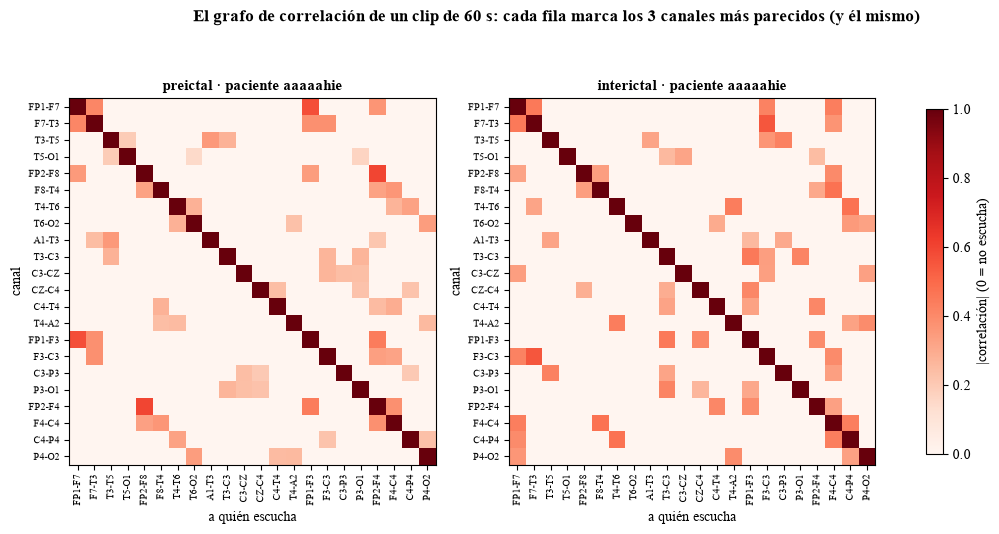

In [7]:
x_ejemplo, _ = datos.lote(np.arange(min(8, len(filas))), k=K)
red_ejemplo = crear_red(red_datos.n_canales, red_datos.n_frecuencias, ARQUITECTURA)
secuencia = red_ejemplo.secuencia_de_segundos(x_ejemplo.cpu())
formas = pd.DataFrame({
    'forma': [str(tuple(x_ejemplo.shape)), str(tuple(secuencia.shape)), f'({x_ejemplo.shape[0]}, 22, 22)',
              f'({x_ejemplo.shape[0]}, 22, {ARQUITECTURA["memoria"]})  × {secuencia.shape[1]} pasos × {ARQUITECTURA["capas"]} capas',
              f'({x_ejemplo.shape[0]},)'],
    'qué es': ['el lote como sale del almacén: (filas, ventanas de 4 s, canales, 4 s × 40 Hz)',
               'reordenado: (filas, segundos, nodos, frecuencias)',
               'el grafo de cada clip: a quién escucha cada canal (3 vecinos + él mismo)',
               'la memoria de cada nodo, que se actualiza cada segundo mezclándose con la de sus vecinos',
               'un logit por fila: el máximo de lo que da cada nodo al final']},
    index=pd.Index(['1 · almacén', '2 · secuencia', '3 · grafo', '4 · DCGRU', '5 · salida'], name='paso'))
display(formas.style.set_properties(**{'text-align': 'left'}))
parametros = pd.DataFrame([contar_parametros(red_ejemplo)], index=['RedDCRNN'])
parametros.index.name = 'red'
display(con_separadores(parametros, decimales=0))
del red_ejemplo

# El grafo de un clip ⏳ y uno 💤 del mismo paciente de 🟡 dev
from tfm_comun.senal.montaje import CANALES_TCP
paciente_ej = pd.Series(pacientes[validar & (y == 1)]).value_counts().index[0]
pos_pre = np.where(validar & (y == 1) & (pacientes == paciente_ej))[0]
pos_int = np.where(validar & (y == 0) & (pacientes == paciente_ej))[0]
ejemplos = {'⏳ preictal': pos_pre[len(pos_pre) // 2], '💤 interictal': pos_int[len(pos_int) // 2]}
red_auxiliar = crear_red(red_datos.n_canales, red_datos.n_frecuencias, ARQUITECTURA)   # solo para reordenar el clip
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.6))
    for ax, (clase, posicion) in zip(axes, ejemplos.items()):
        xg, _ = datos.lote(np.array([posicion]), k=K)
        adyacencia = grafo_correlacion(red_auxiliar.secuencia_de_segundos(xg.cpu()))[0].numpy()
        im = ax.imshow(adyacencia, cmap='Reds', vmin=0, vmax=1)
        ax.set_xticks(range(22))
        ax.set_yticks(range(22))
        ax.set_xticklabels(CANALES_TCP, rotation=90, fontsize=7)
        ax.set_yticklabels(CANALES_TCP, fontsize=7)
        ax.set_title(f'{clase.split(" ", 1)[1]} · paciente {paciente_ej}', fontsize=11, fontweight='bold')
        ax.set_xlabel('a quién escucha')
        ax.set_ylabel('canal')
    fig.colorbar(im, ax=axes, shrink=0.8, label='|correlación| (0 = no escucha)')
    fig.suptitle('El grafo de correlación de un clip de 60 s: cada fila marca los 3 canales más parecidos (y él mismo)',
                 fontsize=12, fontweight='bold')
    fig.savefig(RUTA_FIGURAS / 'grafo_ejemplo.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer las tablas y la figura.** Arriba, la forma de los datos en cada paso y los parámetros (todos en las dos capas DCGRU: son los mismos para los 22 nodos). Abajo, el grafo de un clip ⏳ y de uno 💤 del mismo paciente: cada fila es un canal y en rojo los canales que escucha (más oscuro, más parecidos). La diagonal es él mismo.

✅ **Qué deberías ver:** unos 220.000 parámetros y, en el grafo, vecinos sobre todo **dentro de la misma cadena** del montaje (canales contiguos se parecen). Si el ⏳ muestra bloques distintos al 💤, el grafo aporta información.

## 5. Las variantes

> 🎯 **Qué hacemos:** fijar las dos redes que se entrenan y cómo se entrenan.

- **`dcrnn_60s`** (la principal): el clip entero de 60 s.
- **`dcrnn_12s`**: la misma red con los 12 últimos segundos (los dos clips que usa Tang son 12 y 60 s). Responde a "¿le sirve leer el minuto entero?".

**Cómo se entrena:** exactamente como la red de F03.06, para que la única diferencia sea la red:

| Ajuste | Valor | Por qué |
|---|---|---|
| `evaluaciones_por_epoca` | 4 | En F03.04 la mejor red salía en la época 1: midiendo cada cuarto de época no se pierde el mejor punto |
| `lr` | 3·10⁻⁴ | Un término medio entre F03.04 (10⁻³) y Tang (10⁻⁴): con más pasos de tiempo, la GRU necesita pasos más finos |
| `separacion_s` | 16 | Dos clips seguidos comparten casi todo su minuto: en cada época entra uno de cada 16 s (F03.05, `sin_repetidas`) |
| `equilibrar_clases` | sí | Con la separación quedan distintas ⏳ que 💤 por época: cada clase pesa lo mismo en la pérdida |
| `criterio` | AUC dentro del paciente | La parada temprana elige la época que mejor ordena los momentos de cada persona (F03.05) |
| `epocas_max` | 60 | Cada época es más corta por la separación |

**Tapar frecuencias** va a 0 (la entrada mezcla segundos y frecuencias en el mismo eje). El reflejo de hemisferios no cambia nada en esta red (los pesos son los mismos para todos los nodos), pero se deja igual que en F03.06.

In [8]:
ENTRENAMIENTO_TANG = {**ENTRENAMIENTO, 'evaluaciones_por_epoca': 4, 'lr': 3e-4, 'equilibrar_clases': True, 'epocas_max': 60,
                      'tapar_frecuencias': 0, 'criterio': 'auc_dentro_paciente'}
VARIANTES = {
    f'{NOMBRE_BASE}_60s': {'config': {'arquitectura': dict(ARQUITECTURA), 'entrenamiento': dict(ENTRENAMIENTO_TANG),
                                      'k': K, 'separacion_s': 16, 'entrada': ENTRADA, 'normalizacion': NORMALIZACION_USADA},
                           'qué es': f'la principal: el clip de {K * 4} s, segundo a segundo ({ENTRADA})'},
    f'{NOMBRE_BASE}_12s': {'config': {'arquitectura': dict(ARQUITECTURA), 'entrenamiento': dict(ENTRENAMIENTO_TANG),
                                      'k': 3, 'separacion_s': 16, 'entrada': ENTRADA, 'normalizacion': NORMALIZACION_USADA},
                           'qué es': 'la misma red con los 12 últimos segundos (el clip corto de Tang)'},
}
PRINCIPAL, SIN_CONTEXTO = f'{NOMBRE_BASE}_60s', f'{NOMBRE_BASE}_12s'
if MODO_PRUEBA:
    for v in VARIANTES.values():
        v['config']['entrenamiento']['epocas_max'] = 2
tabla_variantes = pd.DataFrame({n: {'segundos que lee': v['config']['k'] * 4, 'qué es': v['qué es']} for n, v in VARIANTES.items()}).T
tabla_variantes.index.name = 'variante'
display(tabla_variantes.style.set_properties(**{'text-align': 'left'}))

,segundos que lee,qué es
variante,,
dcrnn_60s,60,"la principal: el clip de 60 s, segundo a segundo (log_fft_segundo)"
dcrnn_12s,12,la misma red con los 12 últimos segundos (el clip corto de Tang)


## 6. Entrenar

> 🎯 **Qué hacemos:** entrenar cada variante con 3 semillas (y en cada ronda de validación), puntuar las ventanas de 🟡 dev y apuntarlo en el registro. Si la configuración ya está en el registro con las mismas ventanas, se lee en vez de entrenarse.

> ⏸️ **Se puede parar y seguir.** Cada semilla se apunta en el registro en cuanto acaba (`registro/parciales/`) y, mientras entrena, guarda un punto de control al final de cada época (`puntos_control/`). Si el notebook se corta (un fallo de la GPU, un reinicio), **reinicia el kernel** y vuelve a ejecutarlo: las semillas acabadas se leen y la que estaba a medias sigue desde su última época.

> 💡 La DCRNN es más lenta que la GRU de F03.06 (recorre los 60 segundos paso a paso, con una memoria por nodo): con GPU, del orden de **20-60 minutos** por variante. La segunda vez, segundos.

> 🧱 **Cómo está hecho el código.** El mismo `EntrenadorVariantes` que F03.06 (`tfm_comun/red/entreno/variantes.py`), con `lote_evaluacion = LOTE_EVALUACION` (la DCRNN necesita lotes de validación más pequeños) y puntos de control en `puntos_control/`. Las piezas de la red están cada una en su fichero: `ConvolucionDifusion` (`red/redes/convolucion_difusion.py`), `CeldaDCGRU` (`red/redes/celda_dcgru.py`) y `RedDCRNN` (`red/redes/dcrnn.py`).


In [9]:
# Entrenar (o leer del registro) cada variante: tfm_comun/red/entreno/variantes.py
entrenador = EntrenadorVariantes(red_datos, dispositivo, registro, RUTA_MODELOS, SEMILLAS, CONJUNTO, MODO_PRUEBA,
                                 notebook='F03.08', reentrenar=REENTRENAR, carpeta_puntos_control=RUTA_RESULTADOS / 'puntos_control', lote_evaluacion=LOTE_EVALUACION,
                                 barra=lambda iterable, texto: tqdm(iterable, desc=texto, leave=False))

# Las notas de cada modelo, siempre con las mismas ventanas de 🟡 dev (comun) y los mismos sorteos de pacientes
# (tfm_comun/prediccion/evaluacion/evaluador.py)
evaluador = Evaluador(y, pacientes, comun, especificidad=ESPECIFICIDAD, n_bootstrap=N_BOOTSTRAP, semilla=SEMILLAS[0])

puntuaciones, historiales, resultados = {}, {}, []
inicio_total = time.time()
for nombre, variante in VARIANTES.items():
    config = variante['config']
    h, P, historial, estado, minutos = entrenador.entrenar(nombre, config)
    p = np.full(len(filas), np.nan)
    p[validar] = P[:, validar].mean(axis=0)
    notas = evaluador.notas(p)
    puntuaciones[nombre], historiales[nombre] = p, historial
    columna = 'AUC dentro paciente' if 'AUC dentro paciente' in historial else 'AUC validación'
    mejores_epocas = historial.loc[historial.groupby(['semilla', 'ronda'])[columna].idxmax(), 'época']
    resultados.append({'variante': nombre, **notas,
                       'AUC dentro del paciente de cada semilla': ' · '.join(
                           decimal(auroc_dentro_paciente(y[comun], fila[comun], pacientes[comun])) for fila in P),
                       'mejor época (media)': float(mejores_epocas.mean()),
                       'parámetros': contar_parametros(crear_red(red_datos.n_canales, red_datos.n_frecuencias, config['arquitectura']))['total'],
                       'huella': h, 'estado': estado, 'minutos': minutos})
    registro.guardar(h, {'nombre': nombre, 'fecha': time.strftime('%Y-%m-%d %H:%M'), 'conjunto': CONJUNTO, 'auc_dev': notas['AUC-ROC'],
                         'auc_dentro_paciente': notas['AUC dentro del paciente'], 'semillas': len(SEMILLAS),
                         'configuracion': json.dumps(config, ensure_ascii=False)},
                     P[:, validar], ids_validacion, historial)
resultados = pd.DataFrame(resultados).set_index('variante')
columnas_ver = ['AUC dentro del paciente', 'AUC-ROC', 'AUC dentro del paciente de cada semilla', 'AUC por paciente (mediana)',
                'sensibilidad (esp. 90 %)', 'mejor época (media)', 'parámetros', 'estado', 'minutos']
display(con_separadores(resultados[columnas_ver], decimales=3))
print(f'{len(resultados)} variantes en {numero_legible(round((time.time() - inicio_total) / 60, 1))} min')

dcrnn_12s · semilla 42 · 🟡 dev:   0%|          | 0/60 [00:00<?, ?it/s]

dcrnn_12s · semilla 43 · 🟡 dev:   0%|          | 0/60 [00:00<?, ?it/s]

dcrnn_12s · semilla 44 · 🟡 dev:   0%|          | 0/60 [00:00<?, ?it/s]

,AUC dentro del paciente,AUC-ROC,AUC dentro del paciente de cada semilla,AUC por paciente (mediana),sensibilidad (esp. 90 %),mejor época (media),parámetros,estado,minutos
variante,,,,,,,,,
dcrnn_60s,"0,682","0,648","0,70 · 0,61 · 0,61","0,555","0,242","4,169",223.169,del registro,"0,000"
dcrnn_12s,"0,639","0,599","0,61 · 0,63 · 0,62","0,556","0,121","9,835",223.169,entrenado,"39,295"


2 variantes en 39,5 min


👀 **Cómo leer la tabla.** Una fila por variante: las dos notas en 🟡 dev (media de las semillas): **dentro del paciente** (la que decide) y **global** (AUC-ROC); la nota dentro del paciente de cada semilla (si varían mucho, la red es inestable); la mediana de la AUC por paciente; la sensibilidad con especificidad del 90 %; la **mejor época** (si es muy temprana, sigue memorizando deprisa); y si se ha entrenado ahora o se ha leído del registro.

✅ **Qué deberías ver:** la de 60 s por encima de la de 12 s, y la mejor época más tarde que en F03.06 (columna *mejor época (media)* de su `resultados_dev.csv`): señal de que memoriza más despacio.

### Curvas de aprendizaje

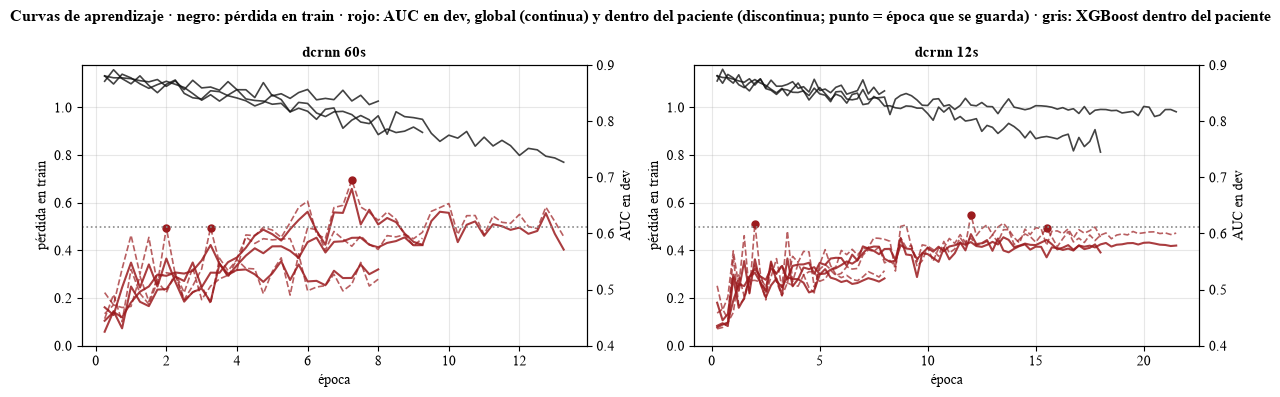

In [10]:
auc_xgb_dentro = auroc_dentro_paciente(y[comun], p_xgb[comun], pacientes[comun])
with plt.rc_context(ESTILO_TIMES):
    fig, axes = plt.subplots(1, len(historiales), figsize=(6.2 * len(historiales), 4), squeeze=False)
    for ax, (nombre, h) in zip(axes.flat, historiales.items()):
        ax2 = ax.twinx()
        for _, hs in h.groupby(['semilla', 'ronda']):
            ax.plot(hs['época'], hs['pérdida train'], color=COLORES_ESQUEMA['negro'], lw=1.2, alpha=0.8)
            ax2.plot(hs['época'], hs['AUC validación'], color=COLORES_ESQUEMA['rojo'], lw=1.5, alpha=0.85)
            if 'AUC dentro paciente' in hs and hs['AUC dentro paciente'].notna().any():
                ax2.plot(hs['época'], hs['AUC dentro paciente'], color=COLORES_ESQUEMA['rojo'], lw=1.2, ls='--', alpha=0.7)
                m = hs.loc[hs['AUC dentro paciente'].idxmax()]
                ax2.plot(m['época'], m['AUC dentro paciente'], 'o', color=COLORES_ESQUEMA['rojo'], ms=5)
        ax2.axhline(auc_xgb_dentro, color=COLORES_ESQUEMA['gris'], ls=':', lw=1.2)
        ax.set_title(nombre.replace('_', ' '), fontsize=11, fontweight='bold')
        ax.set_xlabel('época')
        ax.set_ylabel('pérdida en train')
        ax2.set_ylabel('AUC en dev')
        ax.grid(alpha=0.3)
        ax.set_ylim(bottom=0)
        ax2.set_ylim(0.4, 0.9)
    fig.suptitle('Curvas de aprendizaje · negro: pérdida en train · rojo: AUC en dev, global (continua) y dentro del paciente '
                 '(discontinua; punto = época que se guarda) · gris: XGBoost dentro del paciente', fontsize=11.5, fontweight='bold')
    fig.tight_layout()
    fig.savefig(RUTA_FIGURAS / 'curvas_de_aprendizaje.png', dpi=150, bbox_inches='tight')
    plt.show()

👀 **Cómo leer la figura.** Un panel por variante y una línea por semilla. Negro (eje izquierdo): la pérdida en train, que baja mientras la red aprende (o memoriza). Rojo (eje derecho): la AUC en 🟡 dev, global (continua) y dentro del paciente (discontinua, con un punto en la época que se guarda). Gris de puntos: XGBoost dentro del paciente.

✅ **Qué deberías ver:** la AUC dentro del paciente subiendo durante algo más que la primera época. Si llega al máximo enseguida y luego baja mientras la pérdida de train sigue cayendo, la red sigue aprendiéndose a los pacientes.

## 7. La nota frente a XGBoost y frente a las redes anteriores (F03.06 y F03.05)

> 🎯 **Qué hacemos:** comparar la red principal, con las mismas ventanas de 🟡 dev, con XGBoost de F03.03, con la red sin grafo de F03.06, con la mejor red de F03.05 (si está) y con su variante de 12 s. Diferencia **emparejada** con su intervalo del 95 %, con la nota dentro del paciente y con la global.

![Comparar dos modelos de forma emparejada](img/comparacion_emparejada.png)


In [11]:
p_red = puntuaciones[PRINCIPAL]
notas_red = evaluador.notas(p_red)
notas_xgb = evaluador.notas(p_xgb)
notas_05 = evaluador.notas(p_05) if p_05 is not None else None


comparaciones = [('¿supera a XGBoost DENTRO del paciente?', NOMBRE_XGB, evaluador.diferencia(p_red, p_xgb)),
                 ('¿supera a XGBoost en la nota GLOBAL?', NOMBRE_XGB, evaluador.diferencia(p_red, p_xgb, dentro=False)),
                 ('¿le sirve leer 60 s y no 12 s? (dentro del paciente)', SIN_CONTEXTO, evaluador.diferencia(p_red, puntuaciones[SIN_CONTEXTO]))]
d_05 = d_otra = None
if p_05 is not None:
    d_05 = evaluador.diferencia(p_red, p_05)
    comparaciones.append(('¿supera a la red de F03.05? (dentro del paciente)', NOMBRE_F0305, d_05))
if p_otra is not None:
    d_otra = evaluador.diferencia(p_red, p_otra)
    comparaciones.insert(0, ('¿el grafo mejora la red de F03.06? (dentro del paciente)', NOMBRE_OTRA, d_otra))
d_xgb_dentro, d_xgb_global, d_contexto = [d for q, _, d in comparaciones if 'XGBoost DENTRO' in q][0], \
    [d for q, _, d in comparaciones if 'GLOBAL' in q][0], [d for q, _, d in comparaciones if '60 s' in q][0]
comparacion = pd.DataFrame([{'pregunta': q, 'A': PRINCIPAL, 'B': b, 'diferencia (A − B)': con_signo(d[0]),
                             'IC 95 %': f'{decimal(d[1], 3)} – {decimal(d[2], 3)}', 'lectura': lectura_diferencia(d, MEJORA_MINIMA)} for q, b, d in comparaciones]).set_index('pregunta')

if d_xgb_dentro[1] > 0 and d_xgb_dentro[0] >= MEJORA_MINIMA:
    veredicto = ('✅ La DCRNN supera a XGBoost dentro del paciente', 'la red pasa a ser el modelo de referencia de la fase')
elif d_xgb_dentro[2] < 0:
    veredicto = ('🔴 La DCRNN sigue por debajo de XGBoost dentro del paciente', 'según la regla acordada, la Fase 3 se cierra con XGBoost como modelo de predicción')
else:
    veredicto = ('🟡 Sin diferencia clara con XGBoost dentro del paciente', f'la red queda {"por encima" if d_xgb_dentro[0] > 0 else "por debajo"} '
                 f'({con_signo(d_xgb_dentro[0])}), pero el intervalo incluye el 0: con estos pacientes no se puede decir cuál es mejor')
if MODO_PRUEBA:
    veredicto = ('🔴 MODO PRUEBA · ' + veredicto[0], veredicto[1] + ' (cifras sin valor)')

filas_notas = {f'DCRNN ({PRINCIPAL})': notas_red, f'la misma con 12 s ({SIN_CONTEXTO})': evaluador.notas(puntuaciones[SIN_CONTEXTO]), NOMBRE_XGB: notas_xgb}
if notas_05:
    filas_notas[NOMBRE_F0305] = notas_05
if p_otra is not None:
    filas_notas[NOMBRE_OTRA] = evaluador.notas(p_otra)
tabla_notas = pd.DataFrame({
    'dentro del paciente': [con_intervalo(n['AUC dentro del paciente'], n['_inferior_dentro'], n['_superior_dentro']) for n in filas_notas.values()],
    'global': [con_intervalo(n['AUC-ROC'], n['_inferior'], n['_superior']) for n in filas_notas.values()]},
    index=pd.Index(list(filas_notas), name='AUC en 🟡 dev'))
mostrar_destacado(veredicto[0], 'Las dos notas de cada modelo, con las mismas ventanas de 🟡 dev:', tabla_notas, comparacion,
                  f'<b>Qué significa:</b> {veredicto[1]}.')

👀 **Cómo leer el recuadro.** Arriba, el veredicto con la nota que decide (**dentro del paciente**). La primera tabla da las dos notas de cada modelo con su intervalo; la segunda, las diferencias emparejadas: si el intervalo **no incluye el 0**, la diferencia es real con estos pacientes.

✅ **Qué deberías ver:** la DCRNN por encima de la red sin grafo (F03.06) y, para quedarse, **por encima de XGBoost dentro del paciente** con un intervalo que no incluya el 0 (la regla acordada). Si gana en la nota global pero no dentro del paciente, parte de su nota viene de separar pacientes.

## 8. Por paciente, por grupo de inicio y control de sesión

> 🎯 **Qué hacemos:** ver si la mejora es de la mayoría de pacientes o de unos pocos, en qué grupo de crisis funciona y si la red predice la crisis o reconoce la grabación (control de sesión de F03.03 §10).

In [12]:
modelos = {'DCRNN': p_red, 'XGBoost': p_xgb}
if p_05 is not None:
    modelos['red F03.05'] = p_05
if p_otra is not None:
    modelos['red F03.06'] = p_otra
por_paciente = None
for etiqueta, p in modelos.items():
    pp = auroc_por_paciente(y[comun], p[comun], pacientes[comun])
    columnas = pp[['auroc', '⏳ preictal', '💤 interictal']] if por_paciente is None else pp[['auroc']]
    columnas = columnas.rename(columns={'auroc': f'AUC {etiqueta}'})
    por_paciente = columnas if por_paciente is None else por_paciente.join(columnas)
resumen_pacientes = pd.DataFrame({m: {'mediana de la AUC por paciente': por_paciente[f'AUC {m}'].median(),
                                      'pacientes por encima del azar': int((por_paciente[f'AUC {m}'] > 0.5).sum()),
                                      'pacientes en los que gana a XGBoost': int((por_paciente[f'AUC {m}'] > por_paciente['AUC XGBoost']).sum()) if m != 'XGBoost' else np.nan}
                                  for m in modelos}).T
resumen_pacientes.index.name = f'modelo ({len(por_paciente)} pacientes de dev)'
display(Markdown('**Paciente a paciente**'))
display(con_separadores(resumen_pacientes, decimales=3))

grupos = [g for g in ['focal', 'generalizada', 'ausencia'] if g in set(filas.grupo[comun & (y == 1)].dropna())]
filas_grupo = {}
for g in grupos:
    m = comun & ((y == 0) | (filas.grupo.to_numpy() == g))
    fila = {'pacientes con ⏳': len(set(pacientes[m & (y == 1)]))}
    for etiqueta, p in modelos.items():
        fila[f'AUC {etiqueta}'] = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=1)[0]
    filas_grupo[con_icono(g)] = fila
por_grupo = pd.DataFrame(filas_grupo).T.infer_objects()
por_grupo.index.name = 'grupo de inicio'
display(Markdown('**Por grupo de inicio** (⏳ de ese grupo frente a todas las 💤)'))
display(con_separadores(por_grupo, decimales=3))

controles = controles_de_sesion(comun, y, pacientes, filas.file.to_numpy())
filas_control = {}
for nombre_control, m in controles.items():
    if (y[m] == 0).sum() == 0 or (y[m] == 1).sum() == 0:
        continue
    fila = {'💤 interictal': int((y[m] == 0).sum())}
    for etiqueta, p in modelos.items():
        a, i_, s_ = auroc_con_intervalo(y[m], p[m], pacientes[m], n_bootstrap=N_BOOTSTRAP, semilla=SEMILLAS[0])
        fila[f'AUC {etiqueta}'], fila[f'IC {etiqueta}'] = a, f'{decimal(i_)} – {decimal(s_)}'
    filas_control[nombre_control] = fila
control_sesion = pd.DataFrame(filas_control).T.infer_objects()
control_sesion.index.name = 'qué 💤 se usan'
display(Markdown('**Control de sesión** (F03.03 §10)'))
display(con_separadores(control_sesion, decimales=3))
auc_ses = control_sesion.loc['misma sesión', 'AUC DCRNN'] if 'misma sesión' in control_sesion.index else np.nan
veredicto_sesion = ('✅ Se mantiene' if auc_ses >= notas_red['AUC-ROC'] - 0.05 else '🟡 Baja en la misma sesión') if not np.isnan(auc_ses) else '— sin control'
print(f'Control de sesión de la red: {veredicto_sesion} (misma sesión: {decimal(auc_ses)} · todas: {decimal(notas_red["AUC-ROC"])})')

**Paciente a paciente**

,mediana de la AUC por paciente,pacientes por encima del azar,pacientes en los que gana a XGBoost
modelo (30 pacientes de dev),,,
DCRNN,"0,555","20,000","10,000"
XGBoost,"0,632","24,000",nan
red F03.06,"0,456","13,000","8,000"


**Por grupo de inicio** (⏳ de ese grupo frente a todas las 💤)

,pacientes con ⏳,AUC DCRNN,AUC XGBoost,AUC red F03.06
grupo de inicio,,,,
♦️ focal,"20,000","0,688","0,624","0,590"
🔷 generalizada,"16,000","0,547","0,650","0,507"
🔹 ausencia,"3,000","0,645","0,508","0,562"


**Control de sesión** (F03.03 §10)

,💤 interictal,AUC DCRNN,IC DCRNN,AUC XGBoost,IC XGBoost,AUC red F03.06,IC red F03.06
qué 💤 se usan,,,,,,,
todas las 💤,42.975,"0,648","0,49 – 0,76","0,627","0,57 – 0,69","0,567","0,41 – 0,68"
misma sesión,8.640,"0,655","0,53 – 0,76","0,621","0,57 – 0,70","0,520","0,34 – 0,63"
mismo fichero,1.386,"0,671","0,51 – 0,79","0,685","0,62 – 0,76","0,451","0,27 – 0,58"


Control de sesión de la red: ✅ Se mantiene (misma sesión: 0,66 · todas: 0,65)


👀 **Cómo leer las tablas.** **Paciente a paciente:** la mediana de la AUC dentro de cada paciente, cuántos pacientes quedan por encima del azar (0,5) y en cuántos gana a XGBoost. **Por grupo:** la AUC con las ⏳ de cada grupo de inicio frente a todas las 💤. **Control de sesión:** la AUC con todas las 💤, solo con las de la misma sesión y solo con las del mismo fichero que las ⏳ de cada paciente.

✅ **Qué deberías ver:** la red por encima del azar en la mayoría de pacientes y una AUC con *misma sesión* parecida a la de *todas las 💤*. Si cae mucho, la red reconoce la grabación, no la crisis.

## 9. El resultado → ficheros

In [13]:
guardar = resultados.drop(columns=['_inferior', '_superior', '_inferior_dentro', '_superior_dentro']).assign(
    ic_inferior=resultados._inferior, ic_superior=resultados._superior,
    ic_inferior_dentro=resultados._inferior_dentro, ic_superior_dentro=resultados._superior_dentro).reset_index()
guardar.to_csv(RUTA_RESULTADOS / 'resultados_dev.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'resultados_dev.csv', 'una fila por variante: sus notas en 🟡 dev (dentro del paciente y global, con intervalos), la mejor época y la huella')

puntos = filas.loc[comun, ['id_ventana', 'split', 'patient', 'file', 'clase', 'etiqueta', 'grupo', 'crisis_id']].copy()
for nombre, p in puntuaciones.items():
    puntos[f'puntuacion_{nombre}'] = p[comun].round(5)
puntos['puntuacion_xgboost_f0303'] = p_xgb[comun].round(5)
puntos.to_csv(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'puntuaciones_validacion.csv', 'una fila por ventana de 🟡 dev: la probabilidad de ⏳ de cada variante (media de las semillas) y la de XGBoost')
por_paciente.reset_index().to_csv(RUTA_RESULTADOS / 'auc_por_paciente.csv', index=False)
mostrar_fichero(RUTA_RESULTADOS / 'auc_por_paciente.csv', 'una fila por paciente de 🟡 dev: AUC dentro del paciente de cada modelo')
control_sesion.reset_index().to_csv(RUTA_RESULTADOS / 'control_sesion.csv', index=False)

config = {
    'conjunto': CONJUNTO, 'modo_prueba': MODO_PRUEBA, 'eval_usado': False, 'semillas': SEMILLAS, 'contexto_s': CONTEXTO_S,
    'entrada': ENTRADA, 'normalizacion': NORMALIZACION_USADA,
    'variantes': {n: v['config'] for n, v in VARIANTES.items()},
    'principal': {'variante': PRINCIPAL, 'huella': resultados.loc[PRINCIPAL, 'huella'], 'auc_dev': float(notas_red['AUC-ROC']),
                  'auc_dentro_paciente_dev': float(notas_red['AUC dentro del paciente']),
                  'ic95_dev': [float(notas_red['_inferior']), float(notas_red['_superior'])],
                  'modelos': sorted(str(r.relative_to(RUTA_RESULTADOS)).replace('\\', '/')
                                    for r in RUTA_MODELOS.glob(f'{resultados.loc[PRINCIPAL, "huella"]}_semilla*.pt'))},
    'frente_a_xgboost': {'auc_xgboost': float(notas_xgb['AUC-ROC']), 'auc_dentro_xgboost': float(notas_xgb['AUC dentro del paciente']),
                         'diferencia_dentro': float(d_xgb_dentro[0]), 'ic95_dentro': [float(d_xgb_dentro[1]), float(d_xgb_dentro[2])],
                         'diferencia_global': float(d_xgb_global[0]), 'ic95_global': [float(d_xgb_global[1]), float(d_xgb_global[2])],
                         'veredicto': veredicto[0]},
    'frente_a_12s': {'diferencia_dentro': float(d_contexto[0]), 'ic95_dentro': [float(d_contexto[1]), float(d_contexto[2])]},
    'frente_a_f0306': None if d_otra is None else {'nombre': NOMBRE_OTRA, 'diferencia_dentro': float(d_otra[0]),
                                                          'ic95_dentro': [float(d_otra[1]), float(d_otra[2])]},
    'frente_a_f0305': None if d_05 is None else {'nombre': NOMBRE_F0305, 'diferencia_dentro': float(d_05[0]), 'ic95_dentro': [float(d_05[1]), float(d_05[2])]},
    'control_sesion': veredicto_sesion, 'ventanas_comparadas': int(comun.sum()),
    'dispositivo': ficha['dispositivo'], 'versiones': versiones_usadas, 'fecha': time.strftime('%Y-%m-%d %H:%M'),
}
(RUTA_RESULTADOS / 'configuracion.json').write_text(json.dumps(config, indent=4, ensure_ascii=False, default=str), encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'configuracion.json', 'la configuración de cada variante, la nota de la principal, sus comparaciones y dónde están sus modelos')

💾 **Guardado `resultados_dev.csv`** · 728 B · 2 filas × 15 columnas  
*Qué guarda:* una fila por variante: sus notas en 🟡 dev (dentro del paciente y global, con intervalos), la mejor época y la huella. *Abajo:* las 2 primeras filas.

,variante,AUC dentro del paciente,AUC-ROC,sensibilidad (esp. 90 %),AUC por paciente (mediana),AUC dentro del paciente de cada semilla,mejor época (media),parámetros,huella,estado,minutos,ic_inferior,ic_superior,ic_inferior_dentro,ic_superior_dentro
0,dcrnn_60s,0.682084,0.648201,0.242158,0.555174,"0,70 · 0,61 · 0,61",4.168667,223169,6da6b45f8a,del registro,0.000000,0.494309,0.760302,0.504386,0.802262
1,dcrnn_12s,0.639234,0.599033,0.120835,0.556151,"0,61 · 0,63 · 0,62",9.835000,223169,d4083805c3,entrenado,39.295245,0.517862,0.661850,0.512994,0.711051


💾 **Guardado `puntuaciones_validacion.csv`** · 6,4 MB · 51.168 filas × 11 columnas  
*Qué guarda:* una fila por ventana de 🟡 dev: la probabilidad de ⏳ de cada variante (media de las semillas) y la de XGBoost. *Abajo:* las 5 primeras filas.

,id_ventana,split,patient,file,clase,etiqueta,grupo,crisis_id,puntuacion_dcrnn_60s,puntuacion_dcrnn_12s,puntuacion_xgboost_f0303
0,aaaaaajy_s003_t004_interictal_000000000_000017408,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.47074,0.39471,0.40824
1,aaaaaajy_s003_t004_interictal_000000000_000018432,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.42792,0.38065,0.45209
2,aaaaaajy_s003_t004_interictal_000000000_000019456,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.38934,0.31850,0.59305
3,aaaaaajy_s003_t004_interictal_000000000_000020480,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.40868,0.36886,0.67521
4,aaaaaajy_s003_t004_interictal_000000000_000021504,🟡 dev,aaaaaajy,aaaaaajy_s003_t004,💤 interictal,0,nan,NaN,0.44094,0.45184,0.76313


💾 **Guardado `auc_por_paciente.csv`** · 2,3 KB · 30 filas × 6 columnas  
*Qué guarda:* una fila por paciente de 🟡 dev: AUC dentro del paciente de cada modelo. *Abajo:* las 5 primeras filas.

,paciente,AUC DCRNN,⏳ preictal,💤 interictal,AUC XGBoost,AUC red F03.06
0,aaaaaajy,0.587500,40,26,0.565385,0.006731
1,aaaaabxe,0.825748,58,966,0.742156,0.285054
2,aaaaacyi,0.154813,74,57,0.431958,0.285206
3,aaaaaewf,0.583857,176,477,0.728267,0.661032
4,aaaaaexe,1.000000,148,1,0.837838,0.081081


💾 **Guardado `configuracion.json`** · 4 KB · 18 claves  
*Qué guarda:* la configuración de cada variante, la nota de la principal, sus comparaciones y dónde están sus modelos. *Abajo:* todas las claves (son pocas).

,valor
clave,
conjunto,general
modo_prueba,false
eval_usado,false
semillas,"[42, 43, 44]"
contexto_s,60
entrada,log_fft_segundo
normalizacion,por_paciente_calibrado
variantes,"{""dcrnn_60s"": {""arquitectura"": {""tipo"": ""dcrnn"", ""segundos_por_ventana"": 4, ""memoria"": 64,…"
principal,"{""variante"": ""dcrnn_60s"", ""huella"": ""6da6b45f8a"", ""auc_dev"": 0.6482013256822554, ""auc_dent…"


## 10. Resumen → `summary.txt`

In [14]:
texto = ('=== F03.08 · La red de grafos (DCRNN, grafo de correlación) de Tang ===\n'
         + f'{config["fecha"]} · conjunto {CONJUNTO} · semillas {SEMILLAS} · normalización {NORMALIZACION_USADA}' + (' · MODO PRUEBA' if MODO_PRUEBA else '') + '\n'
         + f'Red ({PRINCIPAL}): dentro del paciente {con_intervalo(notas_red["AUC dentro del paciente"], notas_red["_inferior_dentro"], notas_red["_superior_dentro"])} · '
         + f'global {con_intervalo(notas_red["AUC-ROC"], notas_red["_inferior"], notas_red["_superior"])}\n'
         + f'{NOMBRE_XGB}: dentro {decimal(notas_xgb["AUC dentro del paciente"])} · global {decimal(notas_xgb["AUC-ROC"])}\n'
         + f'Veredicto: {veredicto[0]}\n'
         + f'Frente a XGBoost: dentro {con_signo(d_xgb_dentro[0])} (IC {decimal(d_xgb_dentro[1], 3)} – {decimal(d_xgb_dentro[2], 3)}) · '
         + f'global {con_signo(d_xgb_global[0])} (IC {decimal(d_xgb_global[1], 3)} – {decimal(d_xgb_global[2], 3)})\n'
         + f'60 s frente a 12 s: {con_signo(d_contexto[0])} (IC {decimal(d_contexto[1], 3)} – {decimal(d_contexto[2], 3)})\n'
         + (f'Frente a {NOMBRE_F0305}: {con_signo(d_05[0])} (IC {decimal(d_05[1], 3)} – {decimal(d_05[2], 3)})\n' if d_05 is not None else '')
         + (f'Frente a {NOMBRE_OTRA}: {con_signo(d_otra[0])} (IC {decimal(d_otra[1], 3)} – {decimal(d_otra[2], 3)})\n' if d_otra is not None else '')
         + f'Control de sesión: {veredicto_sesion}\n\n'
         + '--- Variantes ---\n' + resultados[columnas_ver].round(3).to_string() + '\n\n'
         + '--- Paciente a paciente ---\n' + resumen_pacientes.round(3).to_string() + '\n\n'
         + '--- Por grupo ---\n' + por_grupo.round(3).to_string() + '\n\n'
         + '--- Control de sesión ---\n' + control_sesion.round(3).to_string() + '\n')
(RUTA_RESULTADOS / 'summary.txt').write_text(texto, encoding='utf-8')
mostrar_fichero(RUTA_RESULTADOS / 'summary.txt', 'el resumen del notebook en texto')

💾 **Guardado `summary.txt`** · 3,2 KB · 36 líneas  
*Qué guarda:* el resumen del notebook en texto. *Abajo:* las 5 primeras líneas con texto.

,texto
línea,
1,"=== F03.08 · La red de grafos (DCRNN, grafo de correlación) de Tang ==="
2,"2026-11-06 17:19 · conjunto general · semillas [42, 43, 44] · normalización por_paciente_calibrado"
3,"Red (dcrnn_60s): dentro del paciente 0,68 [0,50 – 0,80] · global 0,65 [0,49 – 0,76]"
4,"XGBoost F03.03 (16 s, por_paciente_calibrado): dentro 0,61 · global 0,63"
5,Veredicto: 🟡 Sin diferencia clara con XGBoost dentro del paciente


## 11. Conclusiones

In [15]:
conclusiones = []
if MODO_PRUEBA:
    conclusiones.append('🔴 **MODO PRUEBA:** con un 10 % de las ventanas, 1 semilla y 2 épocas, estas cifras no tienen valor.')
conclusiones.append(f'**1. {veredicto[0]}.** Dentro del paciente: {decimal(notas_red["AUC dentro del paciente"])} frente a {decimal(notas_xgb["AUC dentro del paciente"])} de XGBoost '
                    f'({con_signo(d_xgb_dentro[0])}, IC {decimal(d_xgb_dentro[1], 3)} – {decimal(d_xgb_dentro[2], 3)}: {lectura_diferencia(d_xgb_dentro, MEJORA_MINIMA)}). '
                    f'Global: {decimal(notas_red["AUC-ROC"])} frente a {decimal(notas_xgb["AUC-ROC"])} ({lectura_diferencia(d_xgb_global, MEJORA_MINIMA)}).'
                    + (' La red gana fuera pero no dentro: parte de su nota global viene de separar pacientes.' if d_xgb_global[0] > 0 > d_xgb_dentro[0] else ''))
conclusiones.append(f'**2. ¿Le sirve leer 60 s?** Frente a la misma red con 12 s: {con_signo(d_contexto[0])} (IC {decimal(d_contexto[1], 3)} – {decimal(d_contexto[2], 3)}), '
                    f'{lectura_diferencia(d_contexto, MEJORA_MINIMA)}.')
if d_05 is not None:
    conclusiones.append(f'**3. Frente a la red de F03.05** ({NOMBRE_F0305}): {con_signo(d_05[0])} (IC {decimal(d_05[1], 3)} – {decimal(d_05[2], 3)}), {lectura_diferencia(d_05, MEJORA_MINIMA)}.')
else:
    conclusiones.append('**3. Frente a la red de F03.05:** no se compara (F03.05 no está ejecutado con este conjunto y estas ventanas).')
if d_otra is not None:
    conclusiones.append(f'**3b. ¿El grafo mejora la red de F03.06?** ({NOMBRE_OTRA}): {con_signo(d_otra[0])} '
                        f'(IC {decimal(d_otra[1], 3)} – {decimal(d_otra[2], 3)}), {lectura_diferencia(d_otra, MEJORA_MINIMA)}.')
conclusiones.append(f'**4. Sobreajuste.** Mejor época media de la red principal: {decimal(resultados.loc[PRINCIPAL, "mejor época (media)"], 2)}.'
                    + (' Sigue saliendo muy pronto: la red memoriza deprisa.' if resultados.loc[PRINCIPAL, 'mejor época (media)'] < 1.5 else ''))
conclusiones.append(f'**5. Por paciente.** Mediana de la AUC dentro de cada paciente: {decimal(resumen_pacientes.loc["DCRNN", "mediana de la AUC por paciente"])} '
                    f'(XGBoost {decimal(resumen_pacientes.loc["XGBoost", "mediana de la AUC por paciente"])}); por encima del azar en '
                    f'{int(resumen_pacientes.loc["DCRNN", "pacientes por encima del azar"])} de {len(por_paciente)} pacientes.')
conclusiones.append(f'**6. Control de sesión:** {veredicto_sesion} (misma sesión {decimal(auc_ses)}).')
display(Markdown('\n\n'.join(conclusiones)))

**1. 🟡 Sin diferencia clara con XGBoost dentro del paciente.** Dentro del paciente: 0,68 frente a 0,61 de XGBoost (+0,070, IC -0,163 – 0,259: sin diferencia clara (el intervalo incluye el 0)). Global: 0,65 frente a 0,63 (sin diferencia clara (el intervalo incluye el 0)).

**2. ¿Le sirve leer 60 s?** Frente a la misma red con 12 s: +0,043 (IC -0,050 – 0,109), sin diferencia clara (el intervalo incluye el 0).

**3. Frente a la red de F03.05:** no se compara (F03.05 no está ejecutado con este conjunto y estas ventanas).

**3b. ¿El grafo mejora la red de F03.06?** (red F03.06 sin grafo (gru_segundos_60s)): +0,087 (IC -0,019 – 0,150), sin diferencia clara (el intervalo incluye el 0).

**4. Sobreajuste.** Mejor época media de la red principal: 4,17.

**5. Por paciente.** Mediana de la AUC dentro de cada paciente: 0,56 (XGBoost 0,63); por encima del azar en 20 de 30 pacientes.

**6. Control de sesión:** ✅ Se mantiene (misma sesión 0,66).

## 12. Cómo seguir (la regla acordada)

- **Si la DCRNN supera a XGBoost dentro del paciente** (intervalo sin el 0): pasa a ser el modelo de predicción de la fase. Se puede probar a preentrenarla (F03.07 con esta red) y la evaluación final en 🟢 eval se hace con ella.
- **Si no:** la Fase 3 se cierra con **XGBoost** (F03.03) como modelo de predicción: evaluación final en 🟢 eval (una sola vez), incluida la evaluación en continuo. La DCRNN se reutiliza en la **Fase 4** (clasificación de tipos), donde Tang la usó con éxito.

> 📝 **Para la memoria.** Con F03.04-F03.08 se cuenta la historia completa de las redes: CNN + GRU, escalera de mejoras, clip de 60 s como Tang, entrada por bandas, preentrenamiento y red de grafos, todas con los mismos datos, la misma métrica (AUC dentro del paciente) y el mismo control de sesión.

## 13. Archivos generados

En `outputs/fase_03/<conjunto>/08_red_grafo/`: `resultados_dev.csv`, `puntuaciones_validacion.csv`, `auc_por_paciente.csv`, `control_sesion.csv`, `configuracion.json`, `summary.txt`, `registro/`, `modelos/` y `figuras/` (`grafo_ejemplo.png`, `curvas_de_aprendizaje.png`).